In [1]:
import sys
print(sys.executable)  # путь к Python
print(sys.version)  

/app/.venv/bin/python
3.14.7 (main, Sep 19 2026, 01:01:59) [GCC 14.2.0]


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder
from scipy.stats import zscore
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV


from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier


from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import roc_auc_score, recall_score

from tqdm.auto import tqdm
import optuna

/app/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
import tqdm as notebook_tqdm

In [4]:
import subprocess

subprocess.run(["apt-get", "update", "-qq"], check=True)
subprocess.run(["apt-get", "install", "-y", "-qq", "libgomp1"], check=True)

from lightgbm import LGBMClassifier

In [5]:
import lazypredict

In [6]:
pd.set_option('display.max_columns',  10000)
pd.set_option('display.max_info_columns', 10000)

In [7]:
import os

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine

load_dotenv()

db_name = os.environ["POSTGRES_DB"]
db_user = os.environ["POSTGRES_USER"]
db_password = os.environ["POSTGRES_PASSWORD"]
db_host = os.environ["POSTGRES_HOST"]
db_port = os.environ["POSTGRES_PORT"]

connection_url = (
    f"postgresql+psycopg2://{db_user}:{db_password}"
    f"@{db_host}:{db_port}/{db_name}"
)

engine = create_engine(connection_url)



Загрузить сведения из PostgreSQL на сервере в notebook 

# EDA исходных датасетов

## Выгрузить Train 

In [8]:
df_train = pd.read_sql("SELECT * FROM train",engine)

df_train.head()

,application_id,client_id,employment_type,hash_id,region_coefficient_extended,age,incoming_amount,internal_decision_code,monthly_income,application_date,education,requested_product,channel,loan_amount,marketing_segment,post_loan_collection_score,region_coefficient,region,interest_rate,months_at_job,dependents,days_until_first_overdue,loan_term_months,siberia_northern_score,target
0,107941,7941,employee,61441390.0,1.0,37.0,30401.28,NaN,30401.28,2025-08-11,bachelor,refinance,partner,63464.49,segment_011,800.87,1.0,east,0.3062,31.0,0.0,61.0,24.0,0.336102,1
1,101163,1163,employee,67321556.0,0.0,60.0,26024.64,manual_review_bad,26024.64,2025-12-29,school,card,mobile,113513.59,segment_067,721.57,1.0,ural,0.1383,90.0,0.0,82.0,6.0,0.560893,1
2,100583,583,contractor,26719968.0,0.0,37.0,21389.83,vip,21389.83,2025-11-09,college,cash,NaN,48993.42,NaN,NaN,1.0,west,0.1729,57.0,1.0,999.0,9.0,NaN,0
3,104082,4082,NaN,45184358.0,0.0,NaN,31617.26,approved_auto,NaN,2025-02-23,college,card,web,77765.78,segment_089,170.91,1.0,ural,0.3585,19.0,0.0,999.0,36.0,NaN,0
4,108413,8413,employee,58267524.0,0.0,60.0,18000.00,approved_auto,18000.00,2025-12-07,bachelor,card,mobile,97254.10,segment_063,NaN,1.0,west,0.1472,405.0,0.0,730.0,9.0,0.741053,0


In [9]:
df_train.shape

(6488, 25)

## Оставить признаки для обучения

In [10]:
df_train_10 = df_train[["age","monthly_income", "employment_type","months_at_job", "education","loan_amount","loan_term_months","dependents", "region", "requested_product", "target"]]
df_train_10 


,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product,target
0,37.0,30401.28,employee,31.0,bachelor,63464.49,24.0,0.0,east,refinance,1
1,60.0,26024.64,employee,90.0,school,113513.59,6.0,0.0,ural,card,1
2,37.0,21389.83,contractor,57.0,college,48993.42,9.0,1.0,west,cash,0
3,NaN,NaN,NaN,19.0,college,77765.78,36.0,0.0,ural,card,0
4,60.0,18000.00,employee,405.0,bachelor,97254.10,9.0,0.0,west,card,0
...,...,...,...,...,...,...,...,...,...,...,...
6483,26.0,21480.58,contractor,41.0,master,162310.63,12.0,1.0,north,pos,1
6484,56.0,28198.35,employee,182.0,college,97850.03,NaN,0.0,south,cash,1
6485,50.0,40575.25,contractor,95.0,bachelor,24912.09,12.0,2.0,west,cash,0
6486,56.0,24783.06,employee,184.0,school,70123.74,12.0,NaN,center,cash,0


## Статистический анализ

In [11]:
df_train_10.describe()

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,target
count,6039.000000,6047.000000,6102.000000,5932.000000,5961.000000,6018.000000,6488.000000
mean,43.636529,42300.330501,102.636676,77673.946999,20.849019,0.805085,0.342170
std,13.600516,21759.337138,86.869559,45118.826338,11.907587,0.900978,0.474473
min,21.000000,18000.000000,0.000000,20000.000000,6.000000,0.000000,0.000000
25%,32.000000,26777.040000,36.000000,47056.442500,12.000000,0.000000,0.000000
50%,44.000000,37717.510000,80.000000,67344.210000,18.000000,1.000000,0.000000
75%,55.000000,52181.895000,149.000000,96352.650000,24.000000,1.000000,1.000000
max,67.000000,282686.980000,506.000000,496150.840000,48.000000,5.000000,1.000000


In [12]:
df_train_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 6488 entries, 0 to 6487
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                6039 non-null   float64
 1   monthly_income     6047 non-null   float64
 2   employment_type    6023 non-null   str    
 3   months_at_job      6102 non-null   float64
 4   education          6040 non-null   str    
 5   loan_amount        5932 non-null   float64
 6   loan_term_months   5961 non-null   float64
 7   dependents         6018 non-null   float64
 8   region             5942 non-null   str    
 9   requested_product  6106 non-null   str    
 10  target             6488 non-null   int64  
dtypes: float64(6), int64(1), str(4)
memory usage: 713.0 KB


In [13]:
df_train_10.drop_duplicates(inplace=True)

In [14]:
df_train_10.select_dtypes(include=["object"]).isna().sum()

/tmp/ipykernel_2416/3601982776.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df_train_10.select_dtypes(include=["object"]).isna().sum()


employment_type      465
education            448
region               545
requested_product    382
dtype: int64

In [15]:
# Доля пропусков по каждому столбцу
missing = pd.DataFrame({
    "count": df_train_10.isna().sum(),
    "percent": df_train_10.isna().mean() * 100
})

print(missing.sort_values("percent", ascending=False).round(2))

# Сколько строк имеют хотя бы один пропуск
rows_with_missing = df_train_10.isna().any(axis=1).sum()

print("Строк с пропусками:", rows_with_missing)
print(
    "Доля строк с пропусками, %:",
    round(rows_with_missing / len(df_train_10) * 100, 2)
)

                   count  percent
loan_amount          556     8.58
region               545     8.41
loan_term_months     525     8.10
dependents           468     7.22
employment_type      465     7.18
age                  449     6.93
education            448     6.91
monthly_income       439     6.77
months_at_job        386     5.96
requested_product    382     5.90
target                 0     0.00
Строк с пропусками: 3416
Доля строк с пропусками, %: 52.72


In [16]:
# Количество пропусков в каждой строке
missing_per_row = (df_train_10.isna().mean(axis=1)*100).sort_values(ascending=False).round(2)

# Первые 15 строк с максимальным количеством пропусков
print(
    missing_per_row.head(25)
)

2431    36.36
879     36.36
4409    36.36
4419    36.36
4473    36.36
1596    36.36
886     36.36
5142    36.36
1608    36.36
3605    36.36
1321    36.36
2764    36.36
1130    36.36
5888    36.36
3113    36.36
650     27.27
4522    27.27
4511    27.27
619     27.27
6044    27.27
6008    27.27
134     27.27
3664    27.27
2258    27.27
529     27.27
dtype: float64


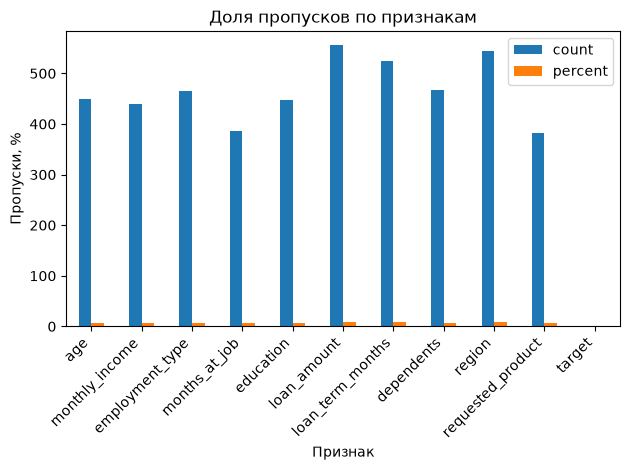

In [17]:
missing = missing[missing > 0]

missing.plot(kind="bar")

plt.title("Доля пропусков по признакам")
plt.xlabel("Признак")
plt.ylabel("Пропуски, %")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

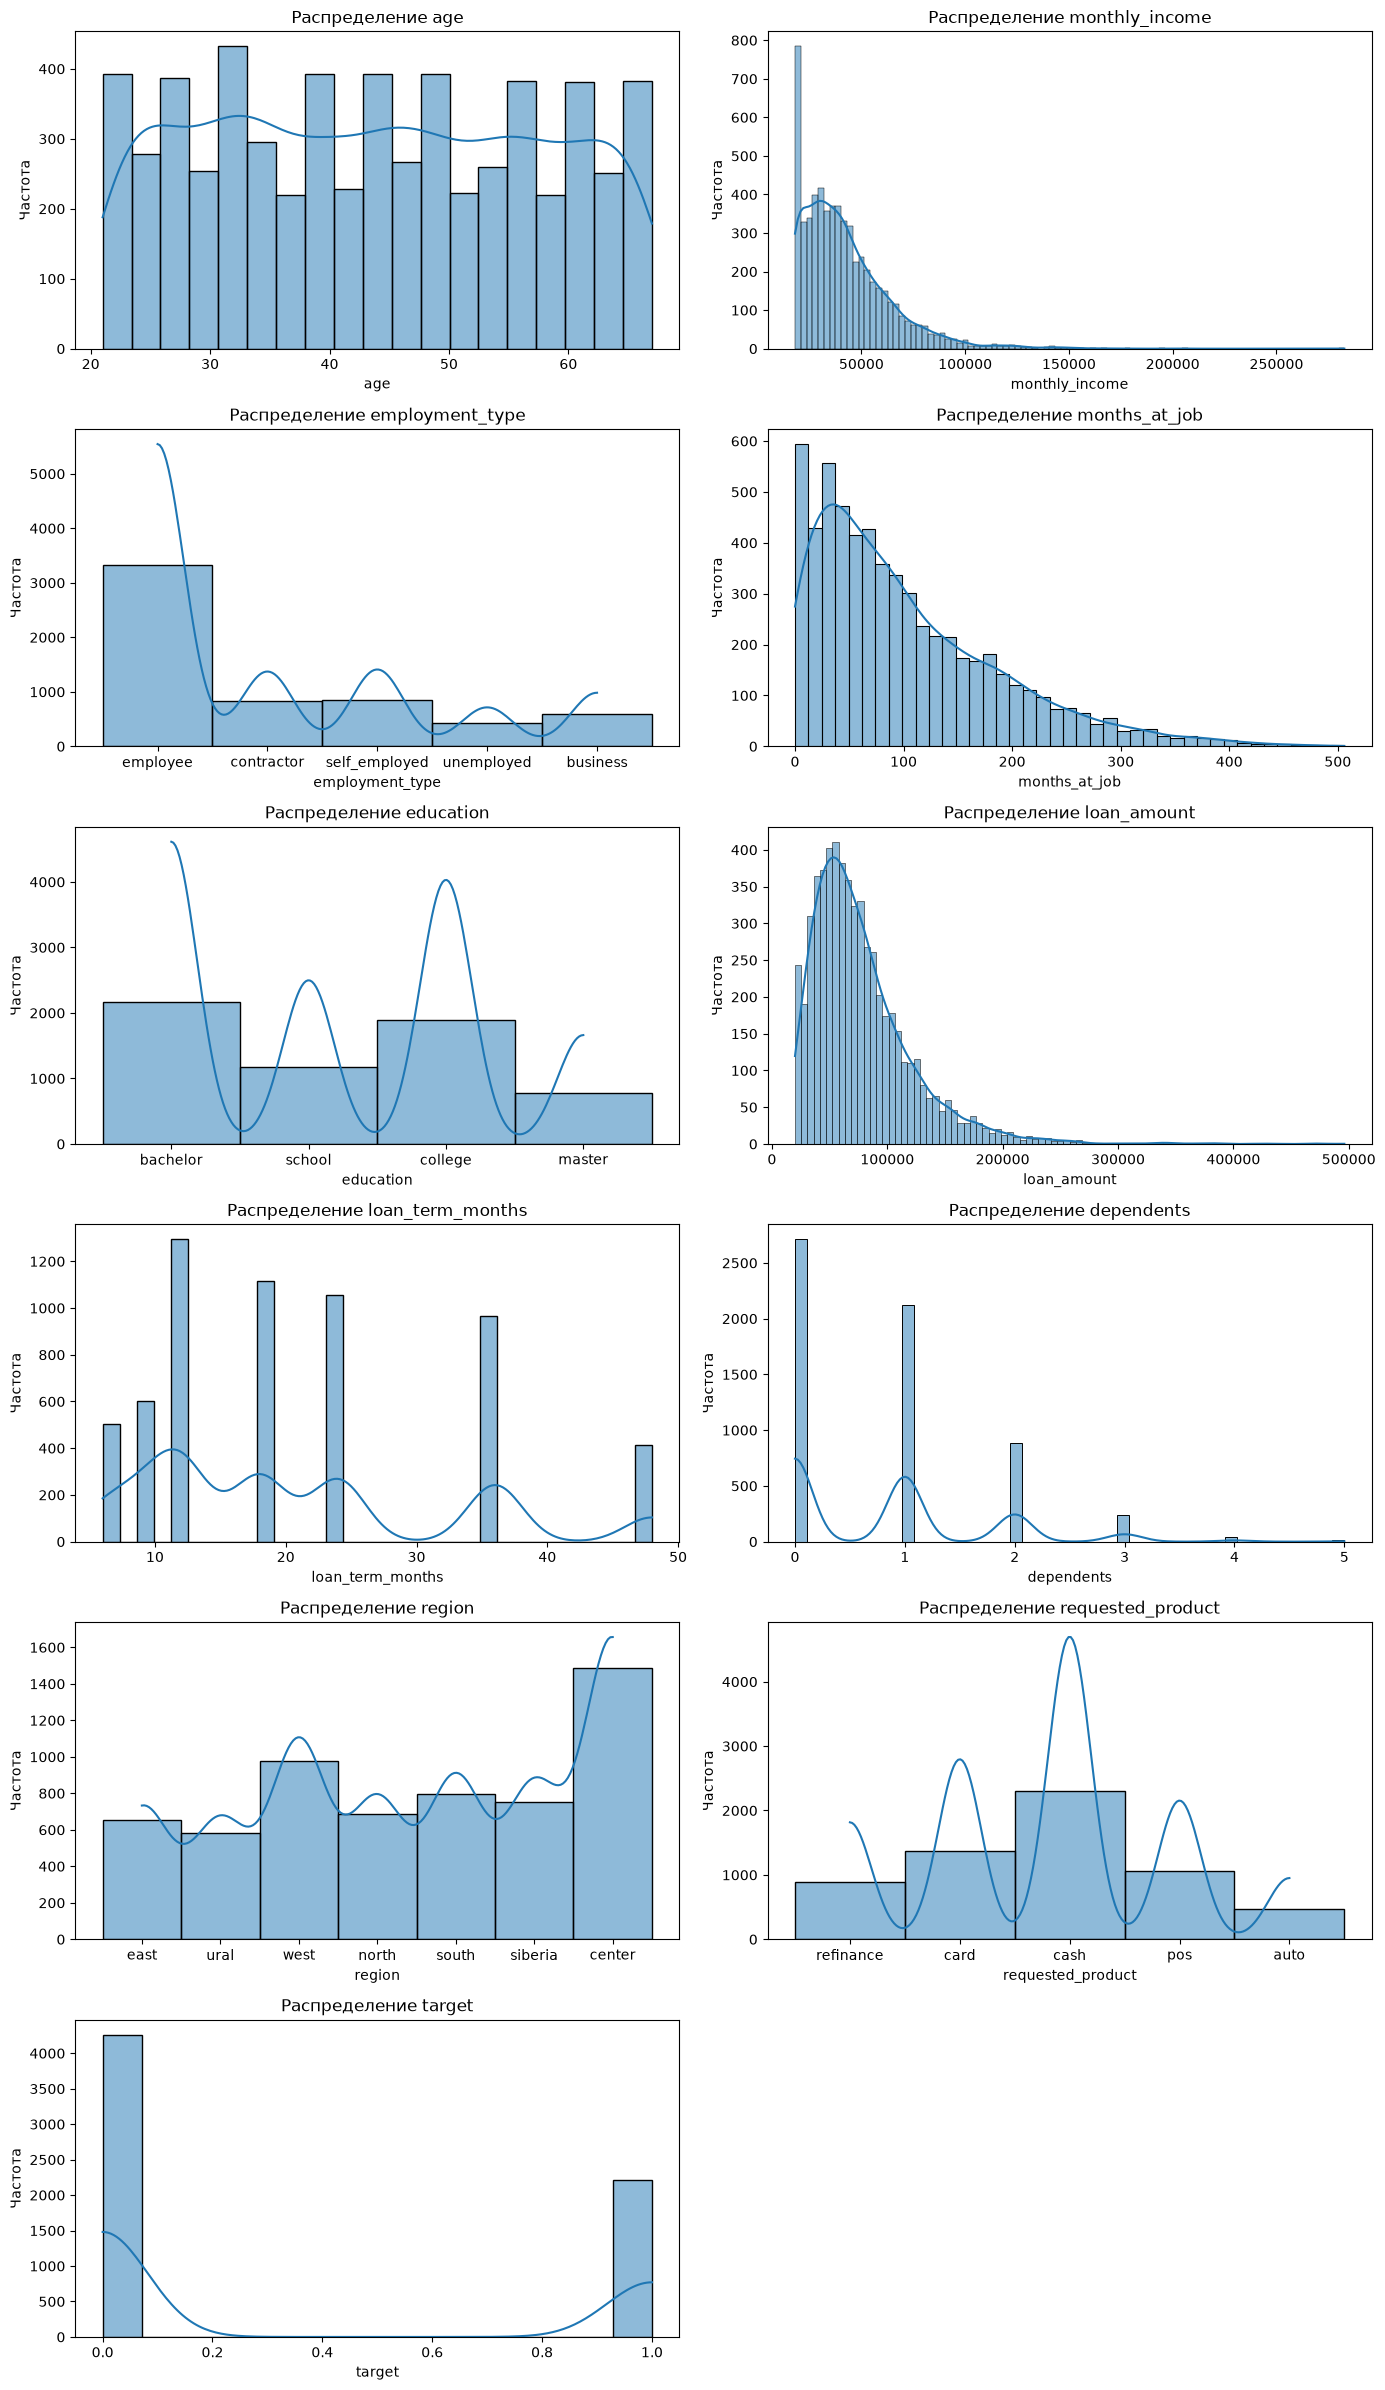

In [18]:
# for col in df_train_10.columns:
#     sns.histplot(kde=True, data=df_train_10, x=col)
#     plt.title(f"Распределение {col}")
#     plt.xlabel(col)
#     plt.ylabel("Частота")
#     plt.show()
    

cols = df_train_10.columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_train_10, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Частота")

# Удаляем пустые области, если число графиков нечётное
for i in range(len(cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

### Разделение данных на test и train

In [19]:
X_train, X_test, y_train, y_test = train_test_split(df_train_10.drop(columns='target'),df_train_10['target'],
    test_size=0.2,random_state=42,stratify=df_train_10['target'])


In [20]:
X_train 

,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product
4088,36.0,53489.61,contractor,NaN,NaN,61504.04,NaN,0.0,north,pos
2829,23.0,29848.22,employee,29.0,bachelor,59656.17,24.0,0.0,ural,cash
2587,21.0,29611.99,employee,24.0,college,NaN,24.0,0.0,ural,auto
2840,29.0,49309.19,employee,NaN,bachelor,38665.65,18.0,2.0,south,auto
5399,57.0,39092.97,contractor,83.0,school,99767.78,24.0,1.0,west,pos
...,...,...,...,...,...,...,...,...,...,...
3032,46.0,26496.29,contractor,86.0,school,84886.66,12.0,NaN,north,cash
2121,50.0,95977.05,business,187.0,college,71021.81,18.0,1.0,south,cash
154,36.0,54601.16,NaN,0.0,bachelor,47676.95,24.0,2.0,north,NaN
1542,44.0,101022.40,employee,149.0,college,69073.49,6.0,1.0,west,card


### Заполнение пропусков 

In [21]:
# df_train_10['age'] = df_train_10['age'].fillna(df_train_10['age'].mean())
cols_num = ['age','loan_term_months','monthly_income','loan_amount','months_at_job',"dependents"]
imputer = KNNImputer(n_neighbors=2)
X_train[cols_num] = imputer.fit_transform(X_train[cols_num])
X_test[cols_num] = imputer.transform(X_test[cols_num])

# df_train_10['loan_term_months'] = df_train_10['loan_term_months'].fillna(df_train_10['loan_term_months'].mean())

In [22]:
# cols = ['monthly_income','loan_amount','months_at_job',"dependents"]
# for col in cols:
#     median = df_train_10[col].median()
#     df_train_10[col] = df_train_10[col].fillna(median)

In [23]:
cat_cols = ["education", "employment_type", "region", "requested_product"]

for col in cat_cols:
    # df_train_10[col] = df_train_10[col].fillna("Unknown")
    mode_value = X_train[col].mode()[0]

    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)


In [24]:
X_train.isnull().sum()

age                  0
monthly_income       0
employment_type      0
months_at_job        0
education            0
loan_amount          0
loan_term_months     0
dependents           0
region               0
requested_product    0
dtype: int64

In [25]:
X_test.isnull().sum()

age                  0
monthly_income       0
employment_type      0
months_at_job        0
education            0
loan_amount          0
loan_term_months     0
dependents           0
region               0
requested_product    0
dtype: int64

### Визуализируем выбросы каждой колонки 

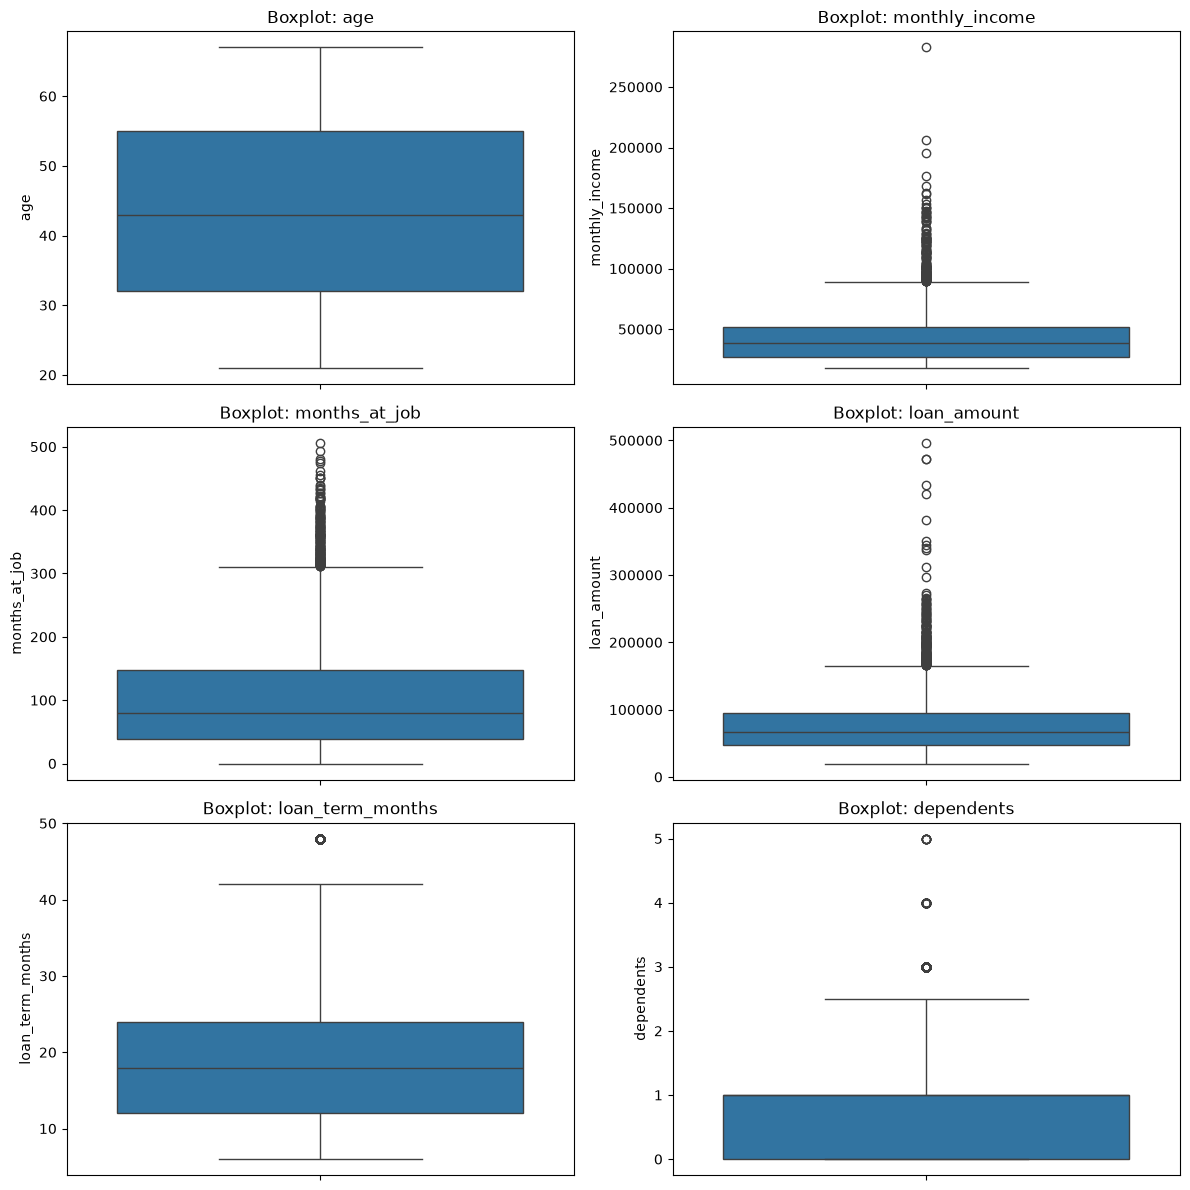

In [26]:
cols = X_train.select_dtypes(include=np.number).columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows,ncols=n_cols,figsize=(12, 4 * n_rows))

axes = axes.flatten()

for idx, feat in enumerate(cols):
    sns.boxplot(y=X_train[feat], ax=axes[idx])
    axes[idx].set_title(f"Boxplot: {feat}")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel(feat)

for idx in range(len(cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

### Для X_test

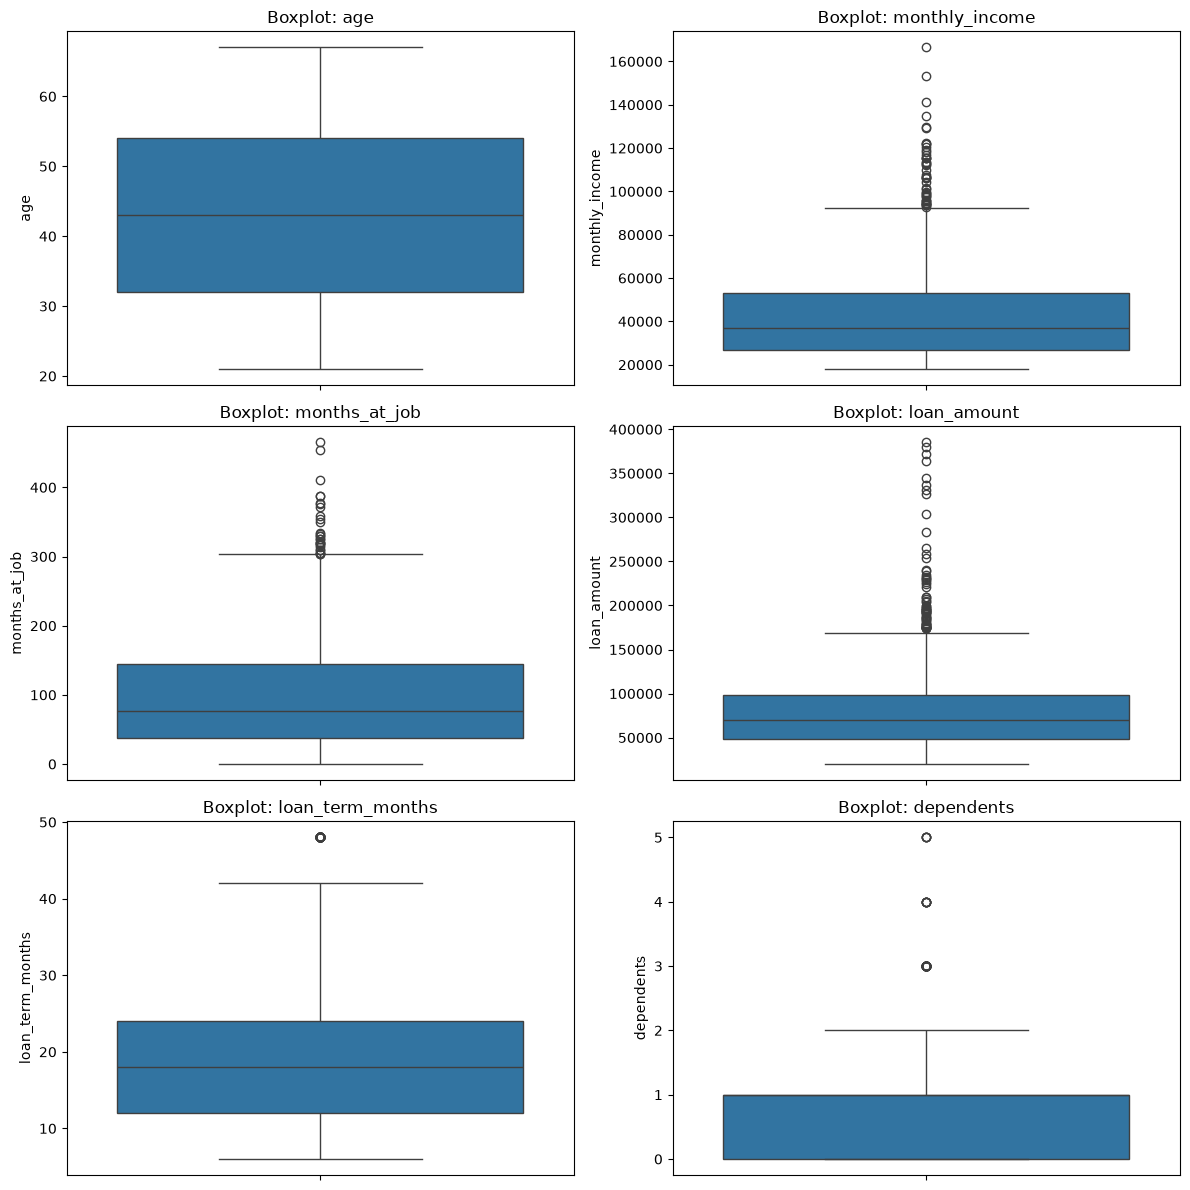

In [27]:
cols = X_test.select_dtypes(include=np.number).columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(nrows=n_rows,ncols=n_cols,figsize=(12, 4 * n_rows))

axes = axes.flatten()

for idx, feat in enumerate(cols):
    sns.boxplot(y=X_test[feat], ax=axes[idx])
    axes[idx].set_title(f"Boxplot: {feat}")
    axes[idx].set_xlabel("")
    axes[idx].set_ylabel(feat)

for idx in range(len(cols), len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

### IQR method для удаления пропусков 

In [28]:
cols_outliers = ['monthly_income', 'loan_amount', 'months_at_job']
for col in cols_outliers:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train[col] = X_train[col].clip(lower, upper)

In [29]:
cols_outliers = ['monthly_income', 'loan_amount', 'months_at_job']
for col in cols_outliers:
    Q1 = X_test[col].quantile(0.25)
    Q3 = X_test[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_test[col] = X_test[col].clip(lower, upper)

### Проверка редких категорий

In [30]:
for col in cat_cols:
    freq = X_train[col].value_counts(normalize=True)
    print(col, freq)

education education
bachelor    0.402971
college     0.293981
school      0.182292
master      0.120756
Name: proportion, dtype: float64
employment_type employment_type
employee         0.585262
self_employed    0.130401
contractor       0.127894
business         0.088735
unemployed       0.067708
Name: proportion, dtype: float64
region region
center     0.315201
west       0.151620
south      0.122492
siberia    0.117670
north      0.104167
east       0.099537
ural       0.089313
Name: proportion, dtype: float64
requested_product requested_product
cash         0.410687
card         0.214699
pos          0.163966
refinance    0.138696
auto         0.071952
Name: proportion, dtype: float64


In [31]:
X_test['education'].unique()

<ArrowStringArray>
['college', 'school', 'bachelor', 'master']
Length: 4, dtype: str

In [32]:
# df_train_10_for_encoding = X_train.copy()

### Кодирование категориальных признаков 

In [33]:
ord_enc = OrdinalEncoder(
    categories=[["school", "college", "bachelor", "master"]],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
    encoded_missing_value=-1
)
# df_train_10_for_encoding["education"] = df_train_10_for_encoding["education"].replace(
#     "Unknown", float("nan")
# )

ord_enc.fit(X_train[["education"]])

X_train["education_enc"] = ord_enc.transform(
    X_train[["education"]]
).ravel()




In [34]:
X_train.drop(columns = "education", inplace=True)


In [35]:
X_train["education_enc"].unique()

array([2., 1., 0., 3.])

In [36]:
X_test["education_enc"] = ord_enc.transform(X_test[["education"]]).ravel()
X_test.drop(columns = "education", inplace=True)

In [37]:
X_test

,age,monthly_income,employment_type,months_at_job,loan_amount,loan_term_months,dependents,region,requested_product,education_enc
23,30.0,79174.050000,employee,28.0,22462.740,12.0,1.0,south,refinance,1.0
2863,42.0,21574.330000,employee,32.0,97970.120,24.0,2.0,north,card,0.0
4283,62.0,72839.550000,employee,173.0,40723.800,18.0,3.0,south,refinance,0.0
1015,38.0,58649.340000,self_employed,93.0,92844.790,18.0,2.0,east,card,1.0
572,62.0,92606.791875,business,179.0,58613.840,6.0,0.0,siberia,refinance,1.0
...,...,...,...,...,...,...,...,...,...,...
2921,37.0,20756.790000,contractor,87.0,24356.570,48.0,1.0,center,cash,1.0
4587,28.0,28675.480000,unemployed,216.0,93447.185,36.0,1.0,center,cash,2.0
4019,64.0,34917.130000,self_employed,83.0,65108.085,12.0,1.0,west,cash,2.0
4582,29.0,18000.000000,unemployed,0.0,66535.700,12.0,1.0,south,cash,2.0


In [38]:
cols_cat_ohe = ["employment_type", "region", "requested_product"]

ohe = OneHotEncoder(sparse_output=False, handle_unknown="ignore")

X_train_ohe = ohe.fit_transform(X_train[cols_cat_ohe].astype(str))
X_test_ohe = ohe.transform(X_test[cols_cat_ohe].astype(str))

X_train_ohe = pd.DataFrame(X_train_ohe,columns=ohe.get_feature_names_out(cols_cat_ohe),index=X_train.index
)

X_test_ohe = pd.DataFrame(X_test_ohe,columns=ohe.get_feature_names_out(cols_cat_ohe),index=X_test.index
)
# Добавляем новые признаки и удаляем исходные категориальные
X_train = pd.concat([X_train.drop(columns=cols_cat_ohe), X_train_ohe], axis=1)
X_test = pd.concat([X_test.drop(columns=cols_cat_ohe), X_test_ohe], axis=1)

In [39]:
X_train

,age,monthly_income,months_at_job,loan_amount,loan_term_months,dependents,education_enc,employment_type_business,employment_type_contractor,employment_type_employee,employment_type_self_employed,employment_type_unemployed,region_center,region_east,region_north,region_siberia,region_south,region_ural,region_west,requested_product_auto,requested_product_card,requested_product_cash,requested_product_pos,requested_product_refinance
4088,36.0,53489.61000,105.5,61504.04,21.0,0.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2829,23.0,29848.22000,29.0,59656.17,24.0,0.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
2587,21.0,29611.99000,24.0,26700.51,24.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2840,29.0,49309.19000,60.5,38665.65,18.0,2.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5399,57.0,39092.97000,83.0,99767.78,24.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3032,46.0,26496.29000,86.0,84886.66,12.0,0.5,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2121,50.0,89467.18875,187.0,71021.81,18.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
154,36.0,54601.16000,0.0,47676.95,24.0,2.0,2.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1542,44.0,89467.18875,149.0,69073.49,6.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Correlation_matrix

<Axes: >

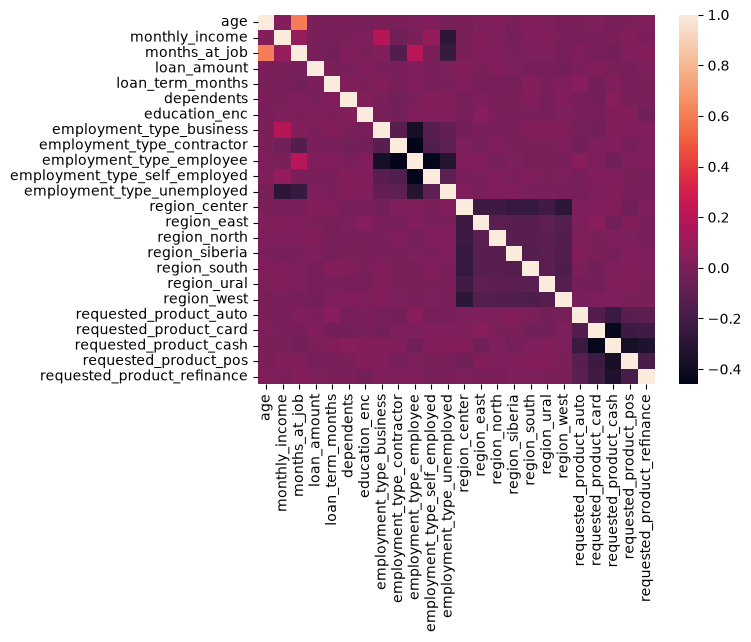

In [40]:
X_train_numeric = X_train.select_dtypes(include=np.number)
corr_matrix = X_train_numeric.corr()
sns.heatmap(corr_matrix, annot=False,fmt=".2f")

In [41]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)


In [42]:
x_train_scaled

array([[-0.53671862,  0.6323366 ,  0.05141771, ..., -0.83479958,
         2.25805747, -0.40128573],
       [-1.50658124, -0.63685341, -0.88875935, ...,  1.19789231,
        -0.44285853, -0.40128573],
       [-1.65579087, -0.64953544, -0.95020883, ..., -0.83479958,
        -0.44285853, -0.40128573],
       ...,
       [-0.53671862,  0.69201026, -1.24516634, ...,  1.19789231,
        -0.44285853, -0.40128573],
       [ 0.06011991,  2.56379594,  0.5860282 , ..., -0.83479958,
        -0.44285853, -0.40128573],
       [-1.65579087,  1.14688612, -0.85188966, ...,  1.19789231,
        -0.44285853, -0.40128573]], shape=(5184, 24))

### Cross validation

In [43]:


# 1. Создаём Logistic Regression и StandardScaler
pipeline = Pipeline([
    # ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# 2. Настраиваем Cross-Validation на 5 фолдов
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
# 3. Выбираем метрики оценки
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# 4. Выполняем Cross-Validation
cv_results = cross_validate(
    estimator=pipeline,
    X=x_train_scaled,
    y=y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
    n_jobs=-1
)

# 5. Выводим результаты по каждому фолду
results_df = pd.DataFrame({
    "ROC AUC": cv_results["test_roc_auc"],
    "Accuracy": cv_results["test_accuracy"],
    "Precision": cv_results["test_precision"],
    "Recall": cv_results["test_recall"],
    "F1": cv_results["test_f1"]
})

display(results_df.round(4))

# 6. Среднее и стандартное отклонение метрик
summary = pd.DataFrame({
    "Mean": results_df.mean(),
    "Std": results_df.std(ddof=0)
})

display(summary.round(4))

,ROC AUC,Accuracy,Precision,Recall,F1
0,0.7451,0.6818,0.5270,0.6873,0.5966
1,0.7053,0.6500,0.4912,0.6254,0.5502
2,0.7038,0.6644,0.5076,0.6592,0.5735
3,0.7182,0.6586,0.5012,0.6028,0.5473
4,0.7357,0.6708,0.5144,0.6554,0.5764


,Mean,Std
ROC AUC,0.7216,0.0164
Accuracy,0.6651,0.0108
Precision,0.5083,0.0121
Recall,0.6460,0.0292
F1,0.5688,0.0182


### Подбор гиперпараметров с помощью GridSearchCV 

In [44]:

# 2. Настраиваем Cross-Validation на 5 фолдов
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Выбираем метрики оценки
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}

# 4. Выполняем Cross-Validation
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit="roc_auc",
    return_train_score=True,
    n_jobs=-1
)



In [45]:
grid_search.fit(x_train_scaled, y_train)

print(grid_search.best_params_)
print(grid_search.best_score_)

# 5. Выводим результаты по каждому фолду
results_df = pd.DataFrame({
    "ROC AUC": grid_search.cv_results_["mean_test_roc_auc"],
    "Accuracy": grid_search.cv_results_["mean_test_accuracy"],
    "Precision": grid_search.cv_results_["mean_test_precision"],
    "Recall": grid_search.cv_results_["mean_test_recall"],
    "F1": grid_search.cv_results_["mean_test_f1"]
})

display(results_df.round(4))



{'classifier__C': 0.1}
0.7216891724287439


,ROC AUC,Accuracy,Precision,Recall,F1
0,0.7214,0.6674,0.5112,0.6381,0.5676
1,0.7216,0.6653,0.5084,0.6483,0.5698
2,0.7217,0.6651,0.5082,0.6466,0.5690
3,0.7216,0.6651,0.5083,0.6460,0.5688
4,0.7216,0.6649,0.5080,0.6460,0.5687
5,0.7216,0.6649,0.5080,0.6460,0.5687
6,0.7216,0.6649,0.5080,0.6460,0.5687


In [46]:
best_model = grid_search.best_estimator_

y_pred = best_model.predict(x_test_scaled)
y_proba = best_model.predict_proba(x_test_scaled)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba))
print("Recall:", recall_score(y_test, y_pred))

ROC AUC: 0.7171652286088905
Recall: 0.6824324324324325


In [47]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

rf_param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [2, 5]
}

rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

rf_grid.fit(x_train_scaled, y_train)

print("Лучшие параметры:", rf_grid.best_params_)
print("Лучший ROC-AUC CV:", rf_grid.best_score_)

best_rf = rf_grid.best_estimator_

Лучшие параметры: {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}
Лучший ROC-AUC CV: 0.7292558082227647


In [48]:
y_pred_rf = best_rf.predict(x_test_scaled)
y_proba_rf = best_rf.predict_proba(x_test_scaled)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba_rf))
print("Recall:", recall_score(y_test, y_pred_rf))

ROC AUC: 0.7297746690352325
Recall: 0.6216216216216216


In [49]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV

cat_model = CatBoostClassifier(
    auto_class_weights="Balanced",
    random_seed=42,
    verbose=0,
    thread_count=1
)

cat_param_grid = {
    "iterations": [300, 500],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.1],
    "l2_leaf_reg": [3, 5]
}

cat_grid = GridSearchCV(
    estimator=cat_model,
    param_grid=cat_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

cat_grid.fit(x_train_scaled, y_train)

print("Лучшие параметры:", cat_grid.best_params_)
print("Лучший ROC-AUC CV:", cat_grid.best_score_)

best_cat = cat_grid.best_estimator_

Лучшие параметры: {'depth': 4, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
Лучший ROC-AUC CV: 0.7348523911832577


In [50]:
y_pred_cat = best_cat.predict(x_test_scaled)
y_proba_cat = best_cat.predict_proba(x_test_scaled)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba_cat))
print("Recall:", recall_score(y_test, y_pred_cat))

ROC AUC: 0.7359366408662182
Recall: 0.6531531531531531


In [51]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV

n_negative = (y_train == 0).sum()
n_positive = (y_train == 1).sum()

scale_pos_weight = n_negative / n_positive

xgb_model = XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    random_state=42,
    n_jobs=1
)

xgb_param_grid = {
    "n_estimators": [300, 500],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

xgb_grid.fit(x_train_scaled, y_train)

print("Лучшие параметры:", xgb_grid.best_params_)
print("Лучший ROC-AUC CV:", xgb_grid.best_score_)

best_xgb = xgb_grid.best_estimator_

Лучшие параметры: {'colsample_bytree': 0.8, 'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 1.0}
Лучший ROC-AUC CV: 0.7345550570350545


In [52]:
y_pred_xgb = best_xgb.predict(x_test_scaled)
y_proba_xgb = best_xgb.predict_proba(x_test_scaled)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba_xgb))
print("Recall:", recall_score(y_test, y_pred_xgb))

ROC AUC: 0.7217966205642261
Recall: 0.6261261261261262


In [53]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

lgbm_model = LGBMClassifier(
    class_weight="balanced",
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

lgbm_param_grid = {
    "n_estimators": [300, 500],
    "learning_rate": [0.03, 0.1],
    "num_leaves": [15, 31, 63],
    "max_depth": [-1, 10, 20],
    "min_child_samples": [20, 50]
}

lgbm_grid = GridSearchCV(
    estimator=lgbm_model,
    param_grid=lgbm_param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    refit=True,
    return_train_score=True
)

lgbm_grid.fit(x_train_scaled, y_train)

print("Лучшие параметры:", lgbm_grid.best_params_)
print("Лучший ROC-AUC CV:", lgbm_grid.best_score_)

best_lgbm = lgbm_grid.best_estimator_

Лучшие параметры: {'learning_rate': 0.03, 'max_depth': 10, 'min_child_samples': 50, 'n_estimators': 300, 'num_leaves': 15}
Лучший ROC-AUC CV: 0.7257720926683418


In [54]:
y_pred_lgbm = best_lgbm.predict(x_test_scaled)
y_proba_lgbm = best_lgbm.predict_proba(x_test_scaled)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_proba_lgbm))
print("Recall:", recall_score(y_test, y_pred_lgbm))

ROC AUC: 0.7169986888296748
Recall: 0.6036036036036037


### Подгрузим df_test_10

In [51]:
df_test = pd.read_sql(
    "SELECT * FROM test",
    engine
)

df_test.head()

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,education,internal_decision_code,monthly_income,region,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,None,38.0,call_center,bachelor,None,34183.79,east,employee,None,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,None,23.0,partner,school,None,18645.00,north,unemployed,None,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,None,12.0,office,bachelor,None,52931.84,ural,employee,None,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,None,179.0,web,college,None,NaN,center,employee,None,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,None,153.0,mobile,bachelor,None,71928.29,center,NaN,None,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09


In [52]:
df_test_10 = df_test[["age","monthly_income", "employment_type","months_at_job", "education","loan_amount","loan_term_months","dependents", "region", "requested_product"]]
df_test_10

,age,monthly_income,employment_type,months_at_job,education,loan_amount,loan_term_months,dependents,region,requested_product
0,NaN,34183.79,employee,38.0,bachelor,73071.51,18.0,0.0,east,refinance
1,64.0,18645.00,unemployed,23.0,school,65408.73,12.0,0.0,north,refinance
2,21.0,52931.84,employee,12.0,bachelor,NaN,36.0,1.0,ural,card
3,55.0,NaN,employee,179.0,college,NaN,6.0,0.0,center,auto
4,55.0,71928.29,NaN,153.0,bachelor,76253.20,12.0,1.0,center,cash
...,...,...,...,...,...,...,...,...,...,...
2515,NaN,34557.28,employee,200.0,college,95337.81,24.0,1.0,north,cash
2516,41.0,47207.94,self_employed,206.0,school,NaN,9.0,2.0,siberia,cash
2517,25.0,25281.07,employee,48.0,college,63097.47,36.0,1.0,ural,auto
2518,31.0,30665.10,employee,90.0,college,148171.13,12.0,1.0,center,pos


In [53]:
df_test_10.info()

<class 'pandas.DataFrame'>
RangeIndex: 2520 entries, 0 to 2519
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                2322 non-null   float64
 1   monthly_income     2284 non-null   float64
 2   employment_type    2365 non-null   str    
 3   months_at_job      2329 non-null   float64
 4   education          2345 non-null   str    
 5   loan_amount        2351 non-null   float64
 6   loan_term_months   2360 non-null   float64
 7   dependents         2365 non-null   float64
 8   region             2284 non-null   str    
 9   requested_product  2328 non-null   str    
dtypes: float64(6), str(4)
memory usage: 257.3 KB


In [54]:
missing_percent_cols = df_test_10.isna().mean() * 100


print(missing_percent_cols.sort_values(ascending=False))

missing_percent_rows = df_test_10.isna().mean(axis=1) * 100

print(missing_percent_rows[missing_percent_rows > 39].sort_values(ascending=False))
# df_missing = df_test_10.loc[missing_percent_rows > 39]

# display(df_missing)

monthly_income       9.365079
region               9.365079
age                  7.857143
requested_product    7.619048
months_at_job        7.579365
education            6.944444
loan_amount          6.706349
loan_term_months     6.349206
employment_type      6.150794
dependents           6.150794
dtype: float64
2366    50.0
236     40.0
90      40.0
699     40.0
769     40.0
1346    40.0
1033    40.0
1368    40.0
1839    40.0
2257    40.0
2499    40.0
dtype: float64


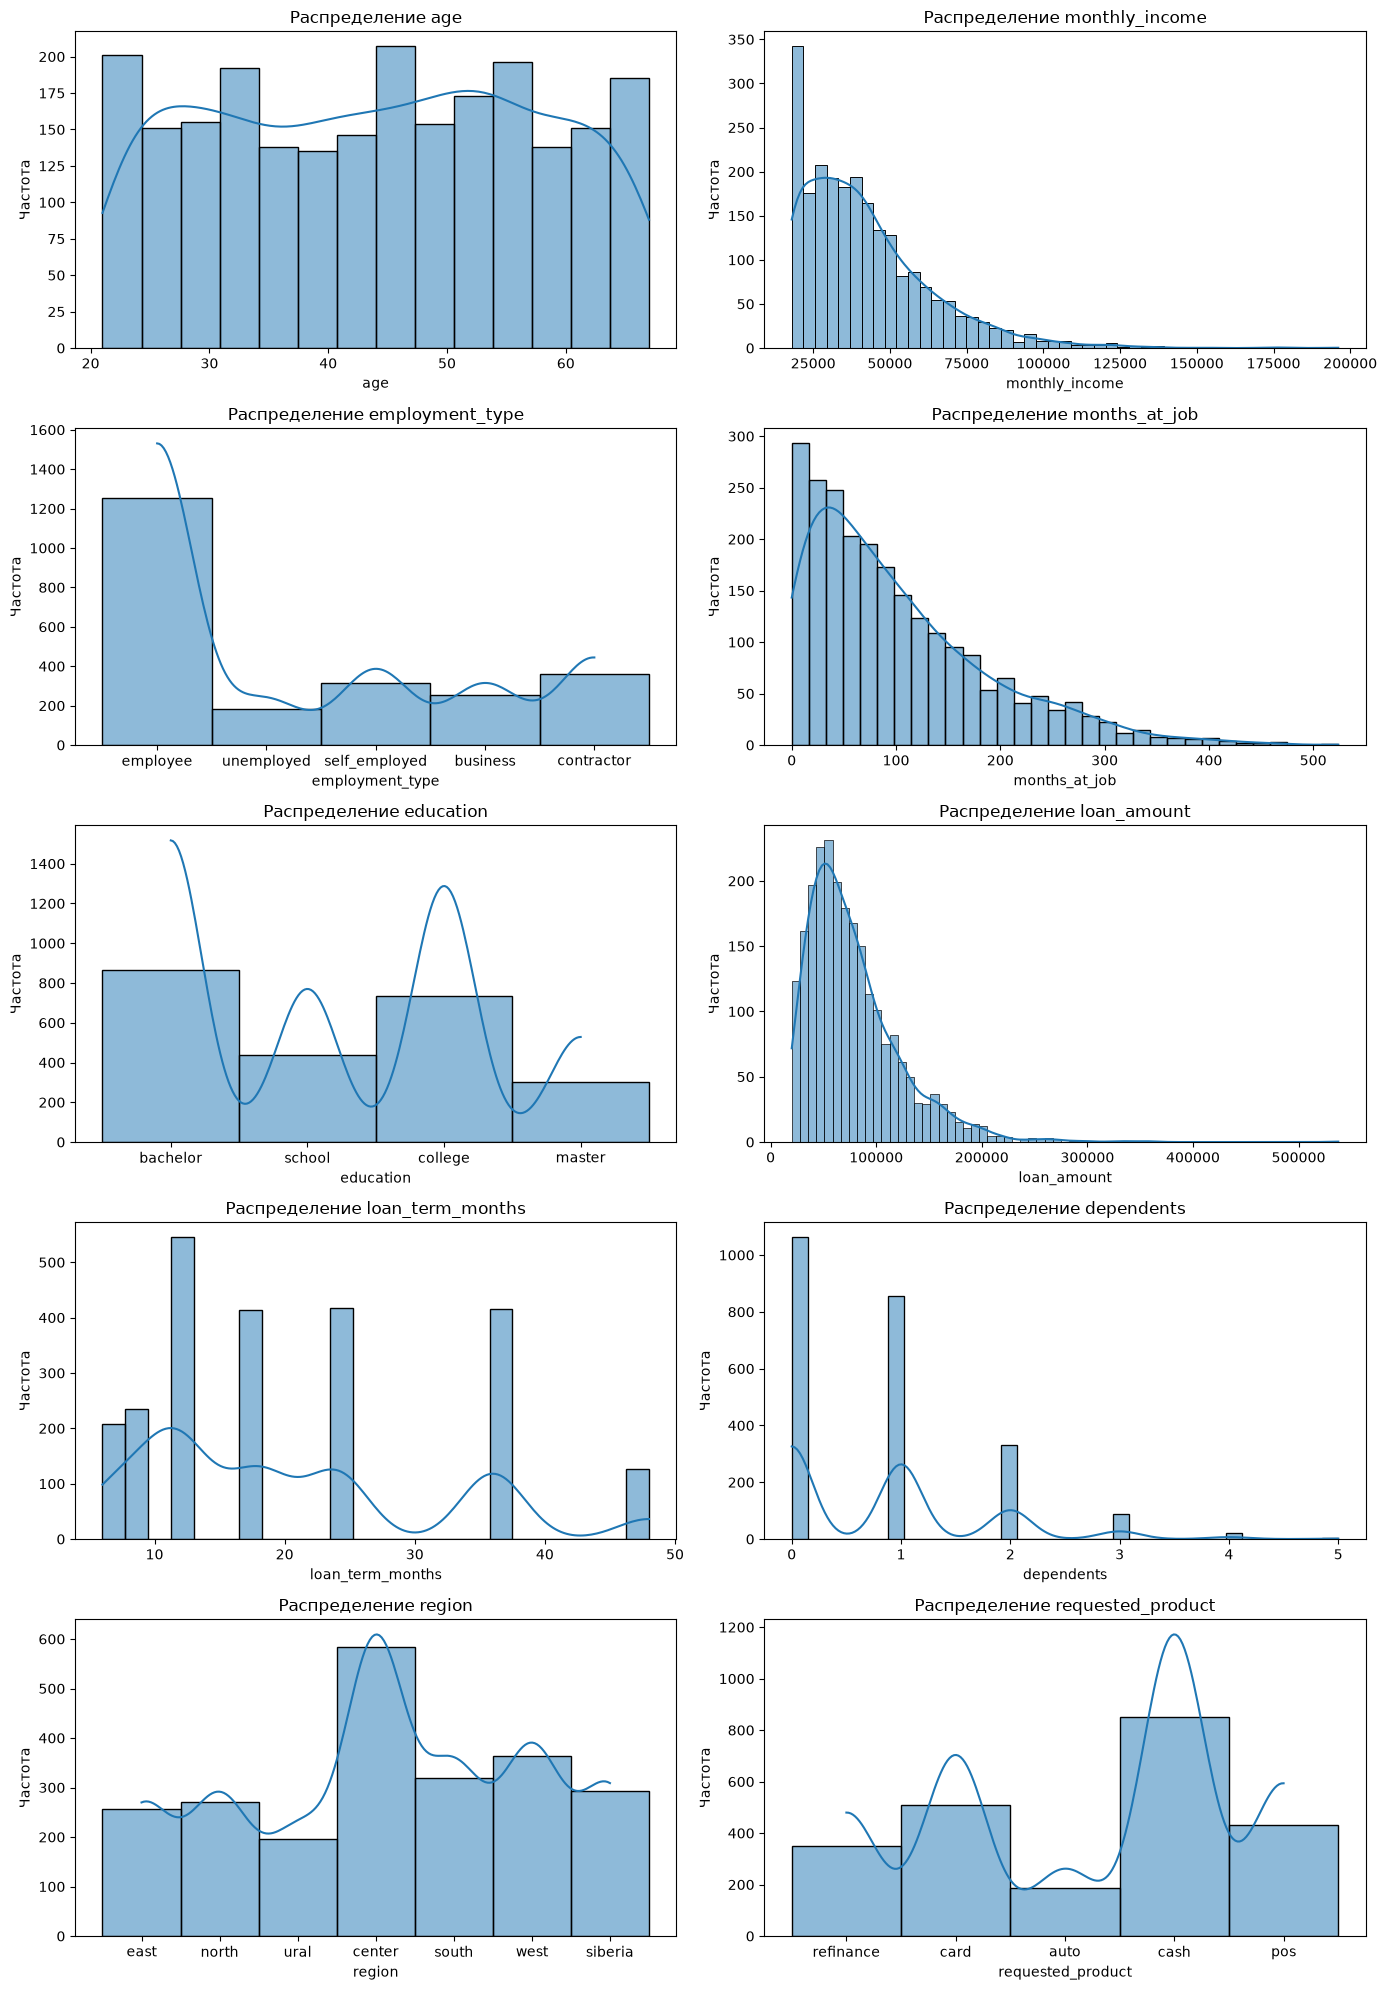

In [55]:
cols = df_test_10.columns
n_cols = 2
n_rows = math.ceil(len(cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(14, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(cols):
    sns.histplot(data=df_test_10, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f"Распределение {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Частота")

# Удаляем пустые области, если число графиков нечётное
for i in range(len(cols), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [ ]:
# df_test_10['age'] = df_test_10['age'].fillna(df_test_10['age'].mean())
# df_test_10['loan_term_months'] = df_test_10['loan_term_months'].fillna(df_test_10['loan_term_months'].mean())

In [ ]:
# cols = ['monthly_income','loan_amount','months_at_job',"dependents"]
# for col in cols:
#     median = df_test_10[col].median()
#     df_test_10[col] = df_test_10[col].fillna(median)

In [ ]:
# cat_cols = ["education", "employment_type", "region", "requested_product"]

# for col in cat_cols:
#     df_test_10[col] = df_test_10[col].fillna(df_test_10[col].mode()[0])
    

In [ ]:
# df_test_10.isna().sum()

age                  0
monthly_income       0
employment_type      0
months_at_job        0
education            0
loan_amount          0
loan_term_months     0
dependents           0
region               0
requested_product    0
dtype: int64

In [ ]:
# df_test_10_for_encoding = df_test_10.copy()

### Кодирование df_test_10

In [ ]:
# df_test_10_for_encoding["education_enc"] = ord_enc.transform(
#     df_test_10_for_encoding[["education"]]
# ).ravel()

# df_test_10_for_encoding.drop(columns = "education", inplace=True)
# df_test_10_for_encoding["education_enc"].unique()

array([2., 0., 1., 3.])

In [ ]:
# cols_cat_label = ["employment_type", "region", "requested_product"]

# for col in cols_cat_label:
#     df_test_10_for_encoding[col] = label_encoders[col].transform(
#         df_test_10_for_encoding[col].astype(str)
#     )

In [ ]:
# df_test_10_for_encoding

,age,monthly_income,employment_type,months_at_job,loan_amount,loan_term_months,dependents,region,requested_product,education_enc
0,43.946598,34183.790,2,38.0,73071.51,18.0,0.0,1,4,2.0
1,64.000000,18645.000,4,23.0,65408.73,12.0,0.0,2,4,0.0
2,21.000000,52931.840,2,12.0,67730.79,36.0,1.0,5,1,2.0
3,55.000000,37825.845,2,179.0,67730.79,6.0,0.0,0,0,1.0
4,55.000000,71928.290,2,153.0,76253.20,12.0,1.0,0,2,2.0
...,...,...,...,...,...,...,...,...,...,...
2515,43.946598,34557.280,2,200.0,95337.81,24.0,1.0,2,2,1.0
2516,41.000000,47207.940,3,206.0,67730.79,9.0,2.0,3,2,0.0
2517,25.000000,25281.070,2,48.0,63097.47,36.0,1.0,5,0,1.0
2518,31.000000,30665.100,2,90.0,148171.13,12.0,1.0,0,3,1.0


### Проведем Масштабирование 

In [ ]:
# df_train_10_for_encoding

,age,monthly_income,employment_type,months_at_job,loan_amount,loan_term_months,dependents,region,requested_product,target,education_enc
0,37.000000,30401.28,2,31.0,63464.49,24.0,0.0,1,4,1,2.0
1,60.000000,26024.64,2,90.0,113513.59,6.0,0.0,5,1,1,0.0
2,37.000000,21389.83,1,57.0,48993.42,9.0,1.0,6,2,0,1.0
3,43.634389,37717.51,2,19.0,77765.78,36.0,0.0,5,1,0,1.0
4,60.000000,18000.00,2,299.0,97254.10,9.0,0.0,6,1,0,2.0
...,...,...,...,...,...,...,...,...,...,...,...
6475,57.000000,73649.90,0,97.0,67331.28,12.0,0.0,4,3,0,2.0
6476,26.000000,45892.80,3,25.0,31477.13,6.0,1.0,1,2,0,1.0
6477,40.000000,46981.28,3,109.0,114445.95,48.0,1.0,4,4,0,0.0
6478,49.000000,31108.33,2,136.0,138748.57,18.0,3.0,6,2,1,3.0


In [ ]:
# X_train = df_train_10_for_encoding.drop(columns='target')
# y_train = df_train_10_for_encoding['target']
# y_train   

0       1
1       1
2       0
3       0
4       0
       ..
6475    0
6476    0
6477    0
6478    1
6479    0
Name: target, Length: 6480, dtype: int64

In [56]:
# X_train, X_test, y_train, y_test = train_test_split(df_train_10_for_encoding.drop(columns='target'),df_train_10_for_encoding['target'],
#     test_size=0.2,random_state=42,stratify=df_train_10_for_encoding['target'])


In [76]:
#instantiate the LinearRegression model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, auc
clf= LogisticRegression(max_iter=1000)
clf.fit(x_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [77]:
# ROC-AUC on train data: predict_proba returns shape (n_samples, 2)
# We need probabilities for the positive class only.
y_proba = clf.predict_proba(x_train_scaled)[:, 1]
roc_auc = roc_auc_score(y_train, y_proba)
print(f"Train ROC AUC: {roc_auc:.4f}")



Train ROC AUC: 0.7128


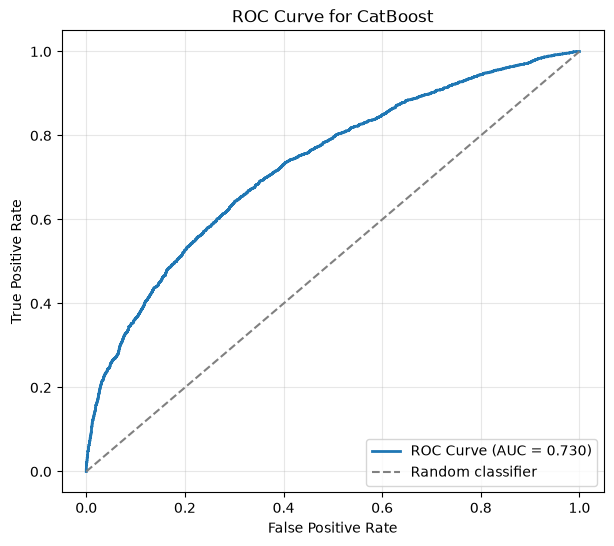

In [365]:
fpr, tpr, thresholds = roc_curve(y_train, y_proba)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.3f})', linewidth=2)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for CatBoost')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()


In [ ]:
# df_test = pd.read_csv('/content/drive/MyDrive/Shift_ML_07.2026/test.csv')
# df_test

,application_id,client_id,region_coefficient_extended,loan_term_months,siberia_northern_score,hash_id,loan_amount,post_loan_collection_score,months_at_job,channel,...,employment_type,days_until_first_overdue,incoming_amount,age,dependents,interest_rate,marketing_segment,region_coefficient,requested_product,application_date
0,102531,2531,0.0,18.0,NaN,NaN,73071.51,NaN,38.0,call_center,...,employee,NaN,34183.79,NaN,0.0,0.2146,segment_112,1.0,refinance,2025-04-25
1,107213,7213,0.0,12.0,0.317813,30012008.0,65408.73,NaN,23.0,partner,...,unemployed,NaN,18645.00,64.0,0.0,0.2851,segment_023,1.0,refinance,2025-05-07
2,100238,238,0.0,36.0,0.902039,92419982.0,NaN,NaN,12.0,office,...,employee,NaN,52931.84,21.0,1.0,0.3810,segment_020,1.0,card,2025-02-26
3,104918,4918,0.0,6.0,0.737848,76137566.0,NaN,NaN,179.0,web,...,employee,NaN,37301.16,55.0,0.0,0.1471,segment_057,1.0,auto,2025-12-07
4,106480,6480,0.0,12.0,0.746599,21845266.0,76253.20,NaN,153.0,mobile,...,NaN,NaN,71928.29,55.0,1.0,0.1840,segment_138,1.0,cash,2025-05-09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2515,105735,5735,0.0,24.0,0.496285,17047133.0,95337.81,NaN,200.0,mobile,...,employee,NaN,34557.28,NaN,1.0,0.2745,segment_139,1.0,cash,2025-10-23
2516,105192,5192,0.0,9.0,0.940226,77377804.0,NaN,NaN,206.0,web,...,self_employed,NaN,NaN,41.0,2.0,0.1992,segment_097,1.0,cash,2025-01-19
2517,105391,5391,0.0,36.0,0.765447,NaN,63097.47,NaN,48.0,partner,...,employee,NaN,25281.07,25.0,1.0,0.3981,segment_057,1.0,auto,2025-10-10
2518,100861,861,0.0,12.0,0.826164,87976929.0,148171.13,NaN,90.0,call_center,...,employee,NaN,30665.10,31.0,1.0,0.2159,segment_123,1.0,pos,2025-05-18


### Проверим идентичны ли столбцы в Train и Test

In [60]:
df_train_cols = set(df_train.columns)
df_test_cols = set(df_test.columns)

if df_train_cols == df_test_cols:
    print("Столбцы идентичны")
else:
    print("Есть различия")

    print("\nЕсть только в df_train:")
    print(df_train_cols - df_test_cols)

    print("\nЕсть только в df_test:")
    print(df_test_cols - df_train_cols)

Есть различия

Есть только в df_train:
{'target'}

Есть только в df_test:
set()
